INPUT DATA SHAPE: (200, 16)
Epoch 20, Reconstruction Error: 0.2548
Epoch 40, Reconstruction Error: 0.2531
Epoch 60, Reconstruction Error: 0.2532
Epoch 80, Reconstruction Error: 0.2512
Epoch 100, Reconstruction Error: 0.2516

HIDDEN LAYER 1 SHAPE: (10, 12)
HIDDEN LAYER 2 SHAPE: (10, 8)

RECONSTRUCTED DATA
[[0.55492965 0.51141044 0.56030277 0.45194817 0.49072287 0.54001862
  0.50333078 0.51977736 0.48503353 0.43695702 0.53942482 0.5060826
  0.47069145 0.45838874 0.528606   0.52285936]
 [0.60158726 0.4684699  0.53069819 0.49804642 0.50801385 0.53804006
  0.52715683 0.57412924 0.54821581 0.44002271 0.45712329 0.48823249
  0.49426858 0.49020381 0.47668379 0.57231127]
 [0.57630154 0.5011518  0.51549032 0.45960613 0.4542212  0.55113951
  0.57596759 0.51864568 0.52785991 0.45315645 0.48690513 0.61129922
  0.52645031 0.5317636  0.51597721 0.52298655]
 [0.59871255 0.53544153 0.48828848 0.47213367 0.44052775 0.56396014
  0.5475103  0.53782806 0.57754033 0.42791158 0.44526457 0.56811328
  0.530279


LEARNED REPRESENTATION SHAPE
(200, 8)


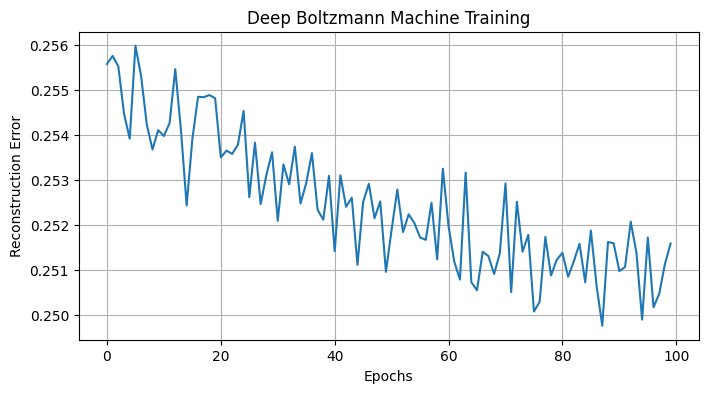

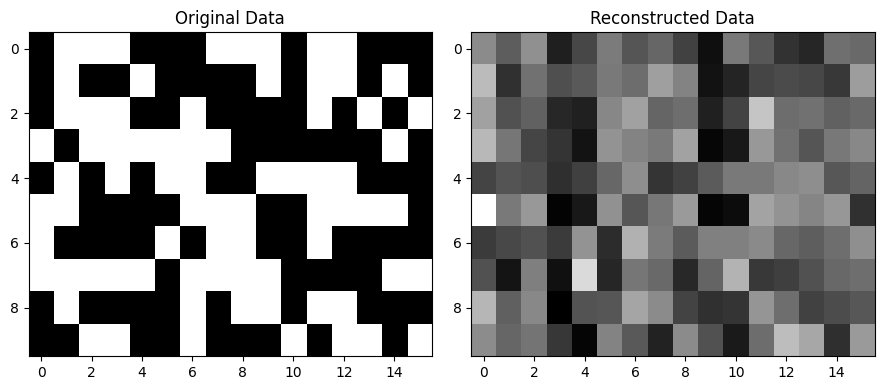

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from scipy.special import expit
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate sample binary dataset
X = np.random.binomial(
    1,
    0.5,
    (200, 16)
).astype(float)

print("INPUT DATA SHAPE:", X.shape)

# 2. Define DBM architecture
n_visible = 16
n_hidden1 = 12
n_hidden2 = 8

# 3. Initialize weights
W1 = np.random.normal(
    0, 0.1,
    (n_visible, n_hidden1)
)

W2 = np.random.normal(
    0, 0.1,
    (n_hidden1, n_hidden2)
)

vb = np.zeros(n_visible)
hb1 = np.zeros(n_hidden1)
hb2 = np.zeros(n_hidden2)

# 4. Gibbs sampling
def gibbs_sampling(v, steps=5):

    h1 = np.zeros(
        (v.shape[0], n_hidden1)
    )

    h2 = np.zeros(
        (v.shape[0], n_hidden2)
    )

    for _ in range(steps):

        # First hidden layer
        p_h1 = expit(
            v @ W1 + h2 @ W2.T + hb1
        )

        h1 = (
            np.random.random(p_h1.shape) < p_h1
        ).astype(float)

        # Second hidden layer
        p_h2 = expit(
            h1 @ W2 + hb2
        )

        h2 = (
            np.random.random(p_h2.shape) < p_h2
        ).astype(float)

        # Visible reconstruction
        p_v = expit(
            h1 @ W1.T + vb
        )

        v = (
            np.random.random(p_v.shape) < p_v
        ).astype(float)

    return p_v, h1, h2

# 5. Train DBM
epochs = 100
learning_rate = 0.01

errors = []

for epoch in range(epochs):

    # Positive phase
    ph1 = expit(X @ W1 + hb1)

    ph2 = expit(ph1 @ W2 + hb2)

    # Negative phase
    nv_prob, nh1, nh2 = gibbs_sampling(
        X.copy(),
        steps=3
    )

    # Update weights
    W1 += learning_rate * (
        X.T @ ph1 - nv_prob.T @ nh1
    ) / len(X)

    W2 += learning_rate * (
        ph1.T @ ph2 - nh1.T @ nh2
    ) / len(X)

    # Update biases
    vb += learning_rate * np.mean(
        X - nv_prob,
        axis=0
    )

    hb1 += learning_rate * np.mean(
        ph1 - nh1,
        axis=0
    )

    hb2 += learning_rate * np.mean(
        ph2 - nh2,
        axis=0
    )

    error = np.mean(
        (X - nv_prob) ** 2
    )

    errors.append(error)

    if (epoch + 1) % 20 == 0:

        print(
            f"Epoch {epoch+1}, "
            f"Reconstruction Error: {error:.4f}"
        )

# 6. Generate reconstructed data
reconstructed, h1, h2 = gibbs_sampling(
    X[:10].copy(),
    steps=10
)

print("\nHIDDEN LAYER 1 SHAPE:", h1.shape)

print("HIDDEN LAYER 2 SHAPE:", h2.shape)

print("\nRECONSTRUCTED DATA")

print(reconstructed)

# 7. Build TensorFlow representation model
representation_model = models.Sequential([
    layers.Input(shape=(16,)),

    layers.Dense(
        12,
        activation="sigmoid"
    ),

    layers.Dense(
        8,
        activation="sigmoid"
    )
])

representation_model.layers[0].set_weights([
    W1,
    hb1
])

representation_model.layers[1].set_weights([
    W2,
    hb2
])

# 8. Extract learned representations
representations = representation_model.predict(
    X,
    verbose=0
)

print("\nLEARNED REPRESENTATION SHAPE")

print(representations.shape)

# 9. Plot reconstruction error
plt.figure(figsize=(8, 4))

plt.plot(errors)

plt.xlabel("Epochs")
plt.ylabel("Reconstruction Error")

plt.title("Deep Boltzmann Machine Training")

plt.grid()

plt.show()

# 10. Visualize original and reconstructed samples
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)

plt.imshow(
    X[:10],
    cmap="gray",
    aspect="auto"
)

plt.title("Original Data")

plt.subplot(1, 2, 2)

plt.imshow(
    reconstructed,
    cmap="gray",
    aspect="auto"
)

plt.title("Reconstructed Data")

plt.tight_layout()

plt.show()